In [1]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: Load the IBM Telco Customer Churn dataset

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Step 3: Display dataset information

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

# Display first 5 rows
df.head()


Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

# Check column names
print("Column Names:")
print(df.columns.tolist())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing Values:
customerID          0
gender  

In [3]:

# Convert TotalCharges into numeric format
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'], errors='coerce'
)

# Check missing values after conversion
print("Missing values after conversion:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Check dataset information
print("\nDataset Information:")
df.info()


Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Duplicate records: 0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null  

Customer Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


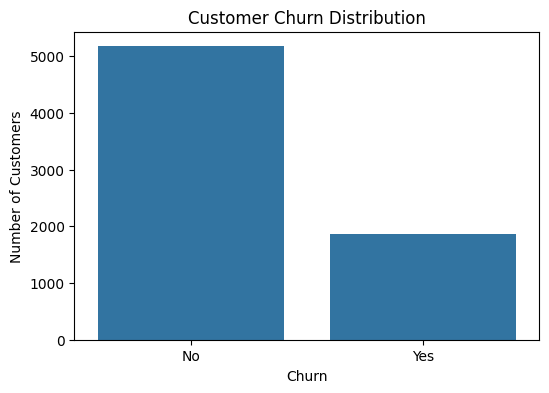

In [4]:

# Count customers who left and stayed
print("Customer Churn Distribution:")
print(df['Churn'].value_counts())

# Visualize churn distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()


Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


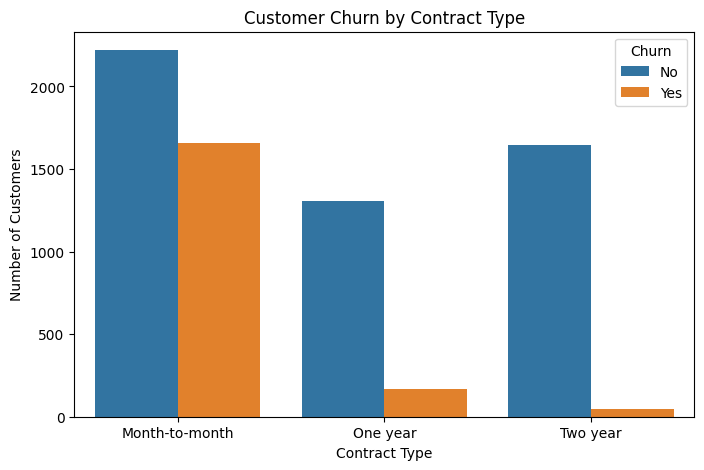

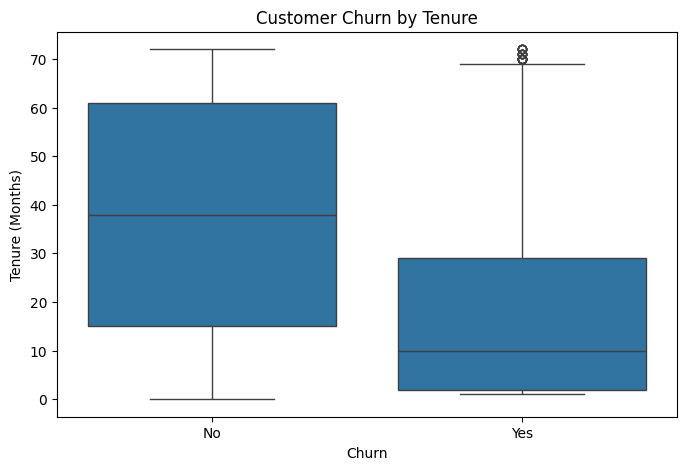

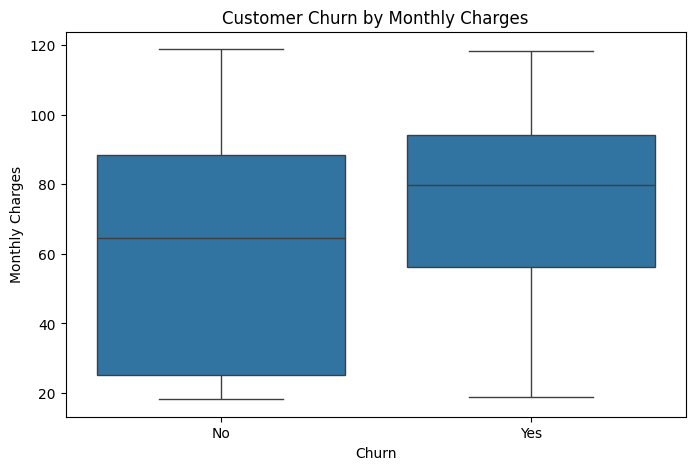

In [5]:

# 1. Churn percentage
churn_percentage = df['Churn'].value_counts(normalize=True) * 100
print("Churn Percentage:")
print(churn_percentage)

# 2. Churn based on contract type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')
plt.show()

# 3. Churn based on tenure
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn', y='tenure')
plt.title('Customer Churn by Tenure')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')
plt.show()

# 4. Churn based on monthly charges
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Customer Churn by Monthly Charges')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')
plt.show()


In [6]:

# Remove customer ID
df = df.drop('customerID', axis=1)

# Remove missing values
df = df.dropna()

# Convert Churn into numerical values
df['Churn'] = df['Churn'].map({
    'Yes': 1,
    'No': 0
})

# Separate input features and target
X = df.drop('Churn', axis=1)
y = df['Churn']

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True)

# Split dataset into training and testing data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data preprocessing completed!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Data preprocessing completed!
Training data: (5625, 30)
Testing data: (1407, 30)


In [7]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train and evaluate models
results = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    results[name] = accuracy

    print("\nModel:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(y_test, y_pred))


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



Model: Logistic Regression
Accuracy: 80.31 %
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407


Model: Decision Tree
Accuracy: 71.86 %
              precision    recall  f1-score   support

           0       0.81      0.81      0.81      1033
           1       0.47      0.46      0.47       374

    accuracy                           0.72      1407
   macro avg       0.64      0.64      0.64      1407
weighted avg       0.72      0.72      0.72      1407


Model: Random Forest
Accuracy: 78.96 %
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
  

                 Model   Accuracy
0  Logistic Regression  80.312722
1        Decision Tree  71.855011
2        Random Forest  78.962331


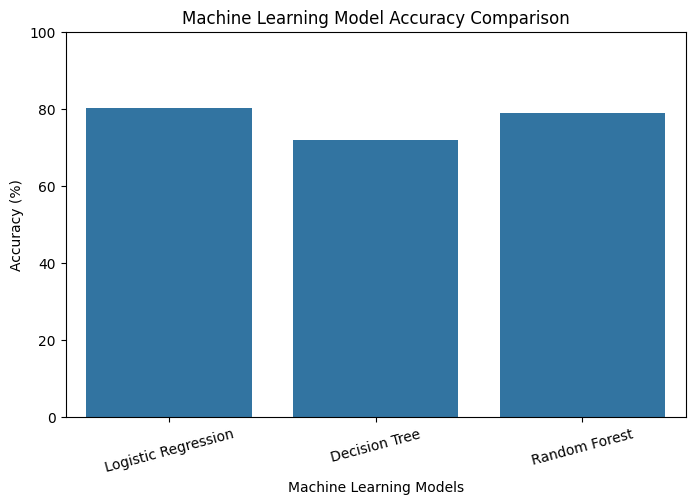

In [8]:

# Compare model accuracy

results_df = pd.DataFrame(
    list(results.items()),
    columns=['Model', 'Accuracy']
)

results_df['Accuracy'] *= 100

print(results_df)

# Create comparison chart
plt.figure(figsize=(8, 5))
sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title('Machine Learning Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.show()


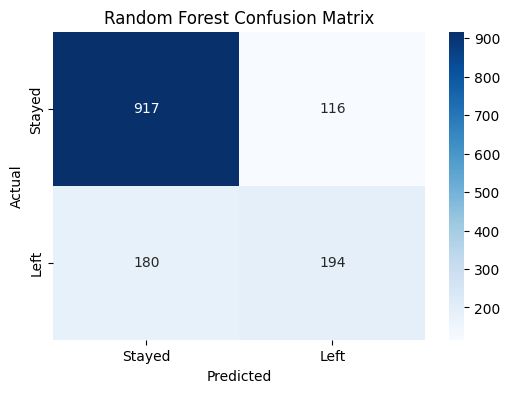

In [9]:

from sklearn.metrics import confusion_matrix

# Predict using Random Forest
rf_model = models['Random Forest']
y_pred = rf_model.predict(X_test)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Stayed', 'Left'],
    yticklabels=['Stayed', 'Left']
)

plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


                           Feature  Importance
3                     TotalCharges    0.191435
1                           tenure    0.171020
2                   MonthlyCharges    0.168400
10     InternetService_Fiber optic    0.039481
28  PaymentMethod_Electronic check    0.037416
25               Contract_Two year    0.030529
4                      gender_Male    0.029332
13              OnlineSecurity_Yes    0.028157
26            PaperlessBilling_Yes    0.025536
19                 TechSupport_Yes    0.024114


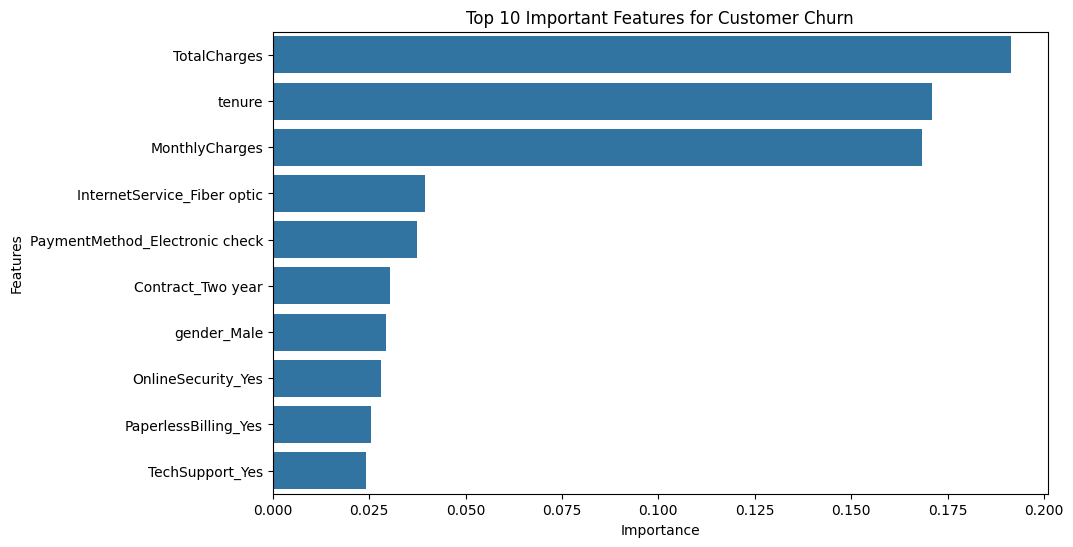

In [10]:

# Get feature importance from Random Forest

importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
importance = importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 10 features
print(importance.head(10))

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Important Features for Customer Churn')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()


# Conclusion

The Customer Churn Prediction project uses Python and Machine Learning to analyze customer behavior and predict customer churn.

### Key Findings
- The dataset contains 7,043 customer records.
- 1,869 customers left the company.
- The overall customer churn rate is approximately 26.54%.
- Random Forest achieved 78.96% accuracy.
- TotalCharges, tenure, and MonthlyCharges were the top three important features in the Random Forest model.

### Machine Learning Models
- Logistic Regression
- Decision Tree
- Random Forest

### Final Result
The project demonstrates how Machine Learning can help businesses identify customers who may leave and support better customer retention strategies.

### Future Improvements
- Improve churn detection using class balancing.
- Tune model hyperparameters.
- Test additional classification algorithms.
- Develop an interactive prediction dashboard.